In [ ]:

from pathlib import Path
import json
import time
import hashlib
from datetime import datetime, timezone

import pandas as pd
import requests

# Folder proyek tugas
PROJECT = Path("/content/akomodasi_kintamani_2501010062")

# Buat struktur folder
folders = [
    "data/raw",
    "data/interim",
    "docs",
    "notebooks",
    "reports"
]

for folder in folders:
    (PROJECT / folder).mkdir(parents=True, exist_ok=True)

print("Folder proyek berhasil disiapkan!")
print("Lokasi:", PROJECT)

for folder in folders:
    print("✓", folder)


Folder proyek berhasil disiapkan!
Lokasi: /content/akomodasi_kintamani_2501010062
✓ data/raw
✓ data/interim
✓ docs
✓ notebooks
✓ reports


In [ ]:

from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

from pathlib import Path

PROJECT = Path(
    "/content/drive/MyDrive/akomodasi_kintamani_2501010062"
)

for folder in [
    "data/raw",
    "data/interim",
    "docs",
    "notebooks",
    "reports"
]:
    (PROJECT / folder).mkdir(
        parents=True,
        exist_ok=True
    )

print("Folder tugas berhasil dibuat!")
print(PROJECT)


Folder tugas berhasil dibuat!
/content/drive/MyDrive/akomodasi_kintamani_2501010062


In [ ]:

URL = "https://overpass-api.de/api/interpreter"

HEADERS = {
    "User-Agent": "INSTIKI-BIFP243-Praktikum/1.0"
}

try:
    response = requests.get(
        "https://overpass-api.de/",
        headers=HEADERS,
        timeout=20
    )
    print("Status koneksi:", response.status_code)

    if response.status_code == 200:
        print("Server dapat dijangkau.")
    else:
        print("Server memberi respons berbeda. Kita periksa lagi.")
except requests.RequestException as error:
    print("Koneksi gagal:", error)


Status koneksi: 200
Server dapat dijangkau.


In [ ]:
import requests
import time

URL = "https://overpass-api.de/api/interpreter"

HEADERS = {
    "User-Agent": "INSTIKI-BIFP243-Praktikum/1.0 (2501010062)"
}

try:
    response = requests.get(
        "https://overpass-api.de/",
        headers=HEADERS,
        timeout=20
    )
    print("Status koneksi:", response.status_code)

    if response.status_code == 200:
        print("Berhasil! Server dapat dijangkau.")
    else:
        print("Server memberi respons berbeda.")

except requests.RequestException as error:
    print("Koneksi gagal:", error)

Status koneksi: 200
Berhasil! Server dapat dijangkau.


In [ ]:

import json
import time
import hashlib
from datetime import datetime, timezone
from pathlib import Path
import requests

# Folder proyek di Google Drive
PROJECT = Path(
    "/content/drive/MyDrive/akomodasi_kintamani_2501010062"
)

RAW_DIR = PROJECT / "data" / "raw"
DOCS_DIR = PROJECT / "docs"

RAW_DIR.mkdir(parents=True, exist_ok=True)
DOCS_DIR.mkdir(parents=True, exist_ok=True)

URL = "https://overpass-api.de/api/interpreter"

HEADERS = {
    "User-Agent": "INSTIKI-BIFP243-Praktikum/1.0 (2501010062)"
}

QUERY = """[out:json][timeout:90];

area["name"="Kintamani"]
["boundary"="administrative"]
["admin_level"="6"]->.kec;

nwr["tourism"~"^(hotel|guest_house|hostel|motel|apartment|chalet)$"]
(area.kec);

out center tags;"""

# Simpan query final
(DOCS_DIR / "query_overpass.txt").write_text(
    QUERY, encoding="utf-8"
)

# Jangan mengirim request berulang jika sebelumnya berhasil.
# Jika gagal, coba ulang maksimal 4 kali dengan jeda meningkat.
data = None

for percobaan in range(1, 5):
    try:
        print(f"Percobaan {percobaan}/4...")

        response = requests.post(
            URL,
            data={"data": QUERY},
            headers=HEADERS,
            timeout=120
        )

        if response.status_code == 200:
            data = response.json()
            break

        print("Status server:", response.status_code)

        if response.status_code not in (429, 500, 502, 503, 504):
            response.raise_for_status()

    except (requests.Timeout, requests.ConnectionError) as error:
        print("Gangguan koneksi:", type(error).__name__)

    except requests.HTTPError as error:
        print("Permintaan gagal:", error)
        break

    if percobaan < 4:
        jeda = 5 * (2 ** (percobaan - 1))
        print(f"Tunggu {jeda} detik sebelum mencoba kembali...")
        time.sleep(jeda)

if data is None:
    raise RuntimeError(
        "Akuisisi gagal. Periksa pesan di atas dan coba lagi nanti."
    )

if "elements" not in data:
    raise ValueError("Respons tidak memiliki elemen data yang diharapkan.")

# Simpan respons mentah tanpa melakukan cleaning
stamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
raw_path = RAW_DIR / f"osm_akomodasi_kintamani_{stamp}.json"

raw_bytes = json.dumps(
    data, ensure_ascii=False, indent=2
).encode("utf-8")

raw_path.write_bytes(raw_bytes)

# Catat informasi akuisisi
md5_hash = hashlib.md5(raw_bytes).hexdigest()

print("\nAKUISISI BERHASIL")
print("Waktu UTC:", datetime.now(timezone.utc).isoformat())
print("Jumlah elemen:", len(data["elements"]))
print("File JSON:", raw_path)
print("Ukuran file:", len(raw_bytes), "byte")
print("MD5:", md5_hash)


Percobaan 1/4...

AKUISISI BERHASIL
Waktu UTC: 2026-11-09T14:05:03.968532+00:00
Jumlah elemen: 32
File JSON: /content/drive/MyDrive/akomodasi_kintamani_2501010062/data/raw/osm_akomodasi_kintamani_20261109_140503.json
Ukuran file: 8492 byte
MD5: b1a575c172357fdeda793f54482c6fd4


In [ ]:

import pandas as pd
import json
from pathlib import Path

PROJECT = Path(
    "/content/drive/MyDrive/akomodasi_kintamani_2501010062"
)

INTERIM_DIR = PROJECT / "data" / "interim"
INTERIM_DIR.mkdir(parents=True, exist_ok=True)

# Pastikan respons akuisisi sudah tersedia
assert "data" in globals(), (
    "Variabel data belum tersedia. Jalankan akuisisi terlebih dahulu."
)

def ratakan(elements):
    baris = []

    for e in elements:
        tags = e.get("tags", {})
        pusat = e.get("center", e)

        baris.append({
            "osm_type": e["type"],
            "osm_id": e["id"],
            "nama": tags.get("name"),
            "jenis": tags.get("tourism"),
            "lat": pusat.get("lat"),
            "lon": pusat.get("lon"),
            "desa": tags.get("addr:village"),
            "bintang": tags.get("stars"),
            "jumlah_kamar": tags.get("rooms"),
            "website": (
                tags.get("website")
                or tags.get("contact:website")
            ),
            "url_osm": (
                f"https://www.openstreetmap.org/"
                f"{e['type']}/{e['id']}"
            )
        })

    return pd.DataFrame(baris)

akomodasi = ratakan(data["elements"])

csv_path = INTERIM_DIR / "akomodasi_kintamani.csv"
akomodasi.to_csv(csv_path, index=False, encoding="utf-8-sig")

print("CSV berhasil disimpan:", csv_path)
print("Jumlah baris:", len(akomodasi))
print("Jumlah kolom:", len(akomodasi.columns))

display(akomodasi.head(10))


CSV berhasil disimpan: /content/drive/MyDrive/akomodasi_kintamani_2501010062/data/interim/akomodasi_kintamani.csv
Jumlah baris: 32
Jumlah kolom: 11


,osm_type,osm_id,nama,jenis,lat,lon,desa,bintang,jumlah_kamar,website,url_osm
0,node,1977779907,The Lakeview Hotel Bali,hotel,-8.283140,115.365844,None,None,None,http://lakeviewbali.com/en/,https://www.openstreetmap.org/node/1977779907
1,node,2107226701,Arlina,guest_house,-8.249815,115.398465,None,None,None,None,https://www.openstreetmap.org/node/2107226701
2,node,2107227001,Toya Devasya Resort,hotel,-8.250164,115.399798,None,None,None,None,https://www.openstreetmap.org/node/2107227001
3,node,4150326329,Guesthouse,hotel,-8.281456,115.362223,None,None,None,None,https://www.openstreetmap.org/node/4150326329
4,node,4297310696,The Cave Hotel,hotel,-8.280748,115.362048,None,2,5,None,https://www.openstreetmap.org/node/4297310696
5,node,4401927990,batur montáin view,hotel,-8.260754,115.338771,None,None,None,None,https://www.openstreetmap.org/node/4401927990
6,node,4863479822,Miranda Homestay & Restaurant,guest_house,-8.246313,115.327402,None,None,None,None,https://www.openstreetmap.org/node/4863479822
7,node,4905949623,Lava Stone Hostel,hostel,-8.250325,115.397136,None,None,None,None,https://www.openstreetmap.org/node/4905949623
8,node,5065920543,The Volcania Guesthouse,hotel,-8.283796,115.365242,None,None,None,None,https://www.openstreetmap.org/node/5065920543
9,node,5175562421,Entrance to: Bunbulan Hill Hostel,hostel,-8.222014,115.395349,None,None,None,None,https://www.openstreetmap.org/node/5175562421


In [ ]:

# Pemeriksaan dasar sesuai instruksi tugas

print("=== RINGKASAN DATA ===")
print("Total baris:", len(akomodasi))

print("\n=== JUMLAH PER JENIS ===")
print(akomodasi["jenis"].value_counts(dropna=False))

print("\n=== NAMA KOSONG ===")
print("Jumlah:", akomodasi["nama"].isna().sum())

print("\n=== DUPLIKAT ID OBJEK ===")
duplikat = akomodasi.duplicated(
    subset=["osm_type", "osm_id"]
)
print("Jumlah baris duplikat:", duplikat.sum())

print("\n=== KOORDINAT KOSONG ===")
print(
    "Latitude kosong:",
    akomodasi["lat"].isna().sum()
)
print(
    "Longitude kosong:",
    akomodasi["lon"].isna().sum()
)

print("\n=== KOLOM YANG BANYAK KOSONG ===")
display(
    akomodasi.isna()
    .sum()
    .rename("jumlah_kosong")
    .to_frame()
    .sort_values("jumlah_kosong", ascending=False)
)


=== RINGKASAN DATA ===
Total baris: 32

=== JUMLAH PER JENIS ===
jenis
hotel          16
guest_house     9
hostel          4
chalet          2
motel           1
Name: count, dtype: int64

=== NAMA KOSONG ===
Jumlah: 1

=== DUPLIKAT ID OBJEK ===
Jumlah baris duplikat: 0

=== KOORDINAT KOSONG ===
Latitude kosong: 0
Longitude kosong: 0

=== KOLOM YANG BANYAK KOSONG ===


,jumlah_kosong
desa,32
bintang,31
jumlah_kamar,30
website,30
nama,1
osm_id,0
osm_type,0
lon,0
lat,0
jenis,0


In [ ]:

ringkasan_jenis = (
    akomodasi["jenis"]
    .value_counts(dropna=False)
    .rename_axis("jenis")
    .reset_index(name="jumlah")
)

ringkasan_jenis.to_csv(
    PROJECT / "data" / "interim" / "ringkasan_per_jenis.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Ringkasan per jenis berhasil disimpan.")


Ringkasan per jenis berhasil disimpan.


In [ ]:

import pandas as pd
from pathlib import Path

PROJECT = Path(
    "/content/drive/MyDrive/akomodasi_kintamani_2501010062"
)
DOCS_DIR = PROJECT / "docs"
DOCS_DIR.mkdir(parents=True, exist_ok=True)

kolom = [
    {
        "kolom": "osm_type",
        "tipe": "teks",
        "deskripsi": "Jenis objek OSM: node, way, atau relation",
        "contoh": "way",
        "boleh_kosong": "Tidak"
    },
    {
        "kolom": "osm_id",
        "tipe": "bilangan bulat",
        "deskripsi": "ID objek di OpenStreetMap",
        "contoh": "123456789",
        "boleh_kosong": "Tidak"
    },
    {
        "kolom": "nama",
        "tipe": "teks",
        "deskripsi": "Nama akomodasi sesuai tag name",
        "contoh": "Nama akomodasi",
        "boleh_kosong": "Ya, wajib dihitung"
    },
    {
        "kolom": "jenis",
        "tipe": "teks",
        "deskripsi": "Nilai tag tourism",
        "contoh": "guest_house",
        "boleh_kosong": "Tidak"
    },
    {
        "kolom": "lat",
        "tipe": "desimal",
        "deskripsi": "Latitude koordinat WGS84",
        "contoh": "-8.27",
        "boleh_kosong": "Tidak"
    },
    {
        "kolom": "lon",
        "tipe": "desimal",
        "deskripsi": "Longitude koordinat WGS84",
        "contoh": "115.37",
        "boleh_kosong": "Tidak"
    },
    {
        "kolom": "desa",
        "tipe": "teks",
        "deskripsi": "Desa sesuai tag addr:village",
        "contoh": "Nama desa",
        "boleh_kosong": "Ya"
    },
    {
        "kolom": "bintang",
        "tipe": "teks",
        "deskripsi": "Klasifikasi bintang dari tag stars",
        "contoh": "3",
        "boleh_kosong": "Ya"
    },
    {
        "kolom": "jumlah_kamar",
        "tipe": "teks",
        "deskripsi": "Jumlah kamar dari tag rooms",
        "contoh": "20",
        "boleh_kosong": "Ya"
    },
    {
        "kolom": "website",
        "tipe": "teks",
        "deskripsi": "Situs resmi akomodasi",
        "contoh": "https://contoh.id",
        "boleh_kosong": "Ya"
    },
    {
        "kolom": "url_osm",
        "tipe": "teks",
        "deskripsi": "Tautan ke objek OpenStreetMap",
        "contoh": "https://www.openstreetmap.org/way/123",
        "boleh_kosong": "Tidak"
    }
]

dictionary = pd.DataFrame(kolom)
dictionary.to_csv(
    DOCS_DIR / "data_dictionary.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Data dictionary berhasil disimpan.")
display(dictionary)


Data dictionary berhasil disimpan.


,kolom,tipe,deskripsi,contoh,boleh_kosong
0,osm_type,teks,"Jenis objek OSM: node, way, atau relation",way,Tidak
1,osm_id,bilangan bulat,ID objek di OpenStreetMap,123456789,Tidak
2,nama,teks,Nama akomodasi sesuai tag name,Nama akomodasi,"Ya, wajib dihitung"
3,jenis,teks,Nilai tag tourism,guest_house,Tidak
4,lat,desimal,Latitude koordinat WGS84,-8.27,Tidak
5,lon,desimal,Longitude koordinat WGS84,115.37,Tidak
6,desa,teks,Desa sesuai tag addr:village,Nama desa,Ya
7,bintang,teks,Klasifikasi bintang dari tag stars,3,Ya
8,jumlah_kamar,teks,Jumlah kamar dari tag rooms,20,Ya
9,website,teks,Situs resmi akomodasi,https://contoh.id,Ya


In [ ]:

import json
import hashlib
from pathlib import Path
from datetime import datetime, timezone

PROJECT = Path(
    "/content/drive/MyDrive/akomodasi_kintamani_2501010062"
)

RAW_DIR = PROJECT / "data" / "raw"
DOCS_DIR = PROJECT / "docs"

raw_files = sorted(RAW_DIR.glob("osm_akomodasi_kintamani_*.json"))

if not raw_files:
    raise FileNotFoundError(
        "JSON mentah tidak ditemukan. Periksa folder data/raw."
    )

# Pilih berkas mentah terbaru berdasarkan nama berkas
raw_path = raw_files[-1]
raw_bytes = raw_path.read_bytes()
data_mentah = json.loads(raw_bytes.decode("utf-8"))

query_path = DOCS_DIR / "query_overpass.txt"
if not query_path.exists():
    raise FileNotFoundError("File query_overpass.txt belum tersedia.")

query = query_path.read_text(encoding="utf-8")

provenance = {
    "endpoint": "https://overpass-api.de/api/interpreter",
    "query": query,
    "waktu_akuisisi_utc": None,
    "catatan_waktu": (
        "Isi waktu UTC yang tercatat saat akuisisi. "
        "Jangan gunakan waktu sekarang sebagai pengganti."
    ),
    "jumlah_elemen": len(data_mentah["elements"]),
    "berkas_mentah": str(raw_path.relative_to(PROJECT)),
    "hash_md5": hashlib.md5(raw_bytes).hexdigest(),
    "lisensi": "Open Database License (ODbL)",
    "atribusi": "© OpenStreetMap contributors",
    "nama_pengambil": "ISI NAMA LENGKAP",
    "nim_pengambil": "2501010062"
}

out_path = DOCS_DIR / "provenance.json"
out_path.write_text(
    json.dumps(provenance, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

print("Provenance awal berhasil dibuat:", out_path)
print("Jumlah elemen aktual:", provenance["jumlah_elemen"])
print("Hash MD5 aktual:", provenance["hash_md5"])
print("Waktu akuisisi perlu dilengkapi jika belum dicatat.")


Provenance awal berhasil dibuat: /content/drive/MyDrive/akomodasi_kintamani_2501010062/docs/provenance.json
Jumlah elemen aktual: 32
Hash MD5 aktual: b1a575c172357fdeda793f54482c6fd4
Waktu akuisisi perlu dilengkapi jika belum dicatat.


In [ ]:

ethics = [
    {
        "aspek": "Sumber data",
        "pemeriksaan": "Menggunakan OpenStreetMap melalui Overpass API",
        "status": "Perlu konfirmasi",
        "bukti_catatan": "Query dan berkas JSON mentah"
    },
    {
        "aspek": "Ketentuan penggunaan",
        "pemeriksaan": "Penggunaan API secara wajar dan tidak berulang tanpa perlu",
        "status": "Perlu konfirmasi",
        "bukti_catatan": "Catatan waktu dan proses akuisisi"
    },
    {
        "aspek": "Lisensi",
        "pemeriksaan": "Mencantumkan lisensi ODbL dan atribusi OSM",
        "status": "Perlu konfirmasi",
        "bukti_catatan": "README dan laporan PDF"
    },
    {
        "aspek": "Minimisasi data",
        "pemeriksaan": "Tidak mengambil nomor telepon, email, atau kontak pemilik",
        "status": "Perlu diperiksa",
        "bukti_catatan": "Kolom dataset dan kode akuisisi"
    },
    {
        "aspek": "Kualitas data",
        "pemeriksaan": "Memeriksa duplikat, nama kosong, dan koordinat",
        "status": "Perlu diperiksa",
        "bukti_catatan": "Output pemeriksaan kualitas"
    },
    {
        "aspek": "Keterbatasan",
        "pemeriksaan": "Menjelaskan bahwa data OSM bisa tidak lengkap",
        "status": "Perlu dilakukan",
        "bukti_catatan": "Laporan dan refleksi"
    }
]

ethics_df = pd.DataFrame(ethics)
ethics_df.to_csv(
    DOCS_DIR / "data_ethics_checklist.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Checklist etika awal berhasil dibuat.")
display(ethics_df)


Checklist etika awal berhasil dibuat.


,aspek,pemeriksaan,status,bukti_catatan
0,Sumber data,Menggunakan OpenStreetMap melalui Overpass API,Perlu konfirmasi,Query dan berkas JSON mentah
1,Ketentuan penggunaan,Penggunaan API secara wajar dan tidak berulang...,Perlu konfirmasi,Catatan waktu dan proses akuisisi
2,Lisensi,Mencantumkan lisensi ODbL dan atribusi OSM,Perlu konfirmasi,README dan laporan PDF
3,Minimisasi data,"Tidak mengambil nomor telepon, email, atau kon...",Perlu diperiksa,Kolom dataset dan kode akuisisi
4,Kualitas data,"Memeriksa duplikat, nama kosong, dan koordinat",Perlu diperiksa,Output pemeriksaan kualitas
5,Keterbatasan,Menjelaskan bahwa data OSM bisa tidak lengkap,Perlu dilakukan,Laporan dan refleksi


In [ ]:

for nama in [
    "data_dictionary.csv",
    "provenance.json",
    "data_ethics_checklist.csv",
    "query_overpass.txt"
]:
    path = PROJECT / "docs" / nama
    print(
        "OK" if path.exists() else "BELUM ADA",
        nama
    )


OK data_dictionary.csv
OK provenance.json
OK data_ethics_checklist.csv
OK query_overpass.txt


In [ ]:

from pathlib import Path
import pandas as pd

PROJECT = Path(
    "/content/drive/MyDrive/akomodasi_kintamani_2501010062"
)

csv_path = PROJECT / "data/interim/akomodasi_kintamani.csv"

if not csv_path.exists():
    raise FileNotFoundError(
        "CSV akomodasi tidak ditemukan. Periksa folder data/interim."
    )

df = pd.read_csv(csv_path)

# Jumlah baris yang benar-benar tercatat dalam CSV
jumlah_osm = len(df)

# Data BPS Kabupaten Bangli, Podes 2021
bps_hotel = 19
bps_penginapan = 39
jumlah_bps = bps_hotel + bps_penginapan

persentase = (
    jumlah_osm / jumlah_bps * 100
    if jumlah_bps > 0 else None
)

perbandingan = pd.DataFrame([{
    "wilayah": "Kecamatan Kintamani",
    "sumber_bps": "Kecamatan Kintamani Dalam Angka 2023, Tabel 6.1.1",
    "tahun_data_bps": 2021,
    "jumlah_hotel_bps": bps_hotel,
    "jumlah_penginapan_bps": bps_penginapan,
    "total_bps": jumlah_bps,
    "tanggal_akses_osm": None,
    "jumlah_baris_osm": jumlah_osm,
    "persentase_perbandingan": round(persentase, 2),
    "catatan": (
        "Perbandingan indikatif. Tahun dan klasifikasi OSM "
        "tidak sepenuhnya sama dengan data BPS."
    )
}])

output = PROJECT / "docs/perbandingan_bps.csv"
output.parent.mkdir(parents=True, exist_ok=True)

perbandingan.to_csv(
    output,
    index=False,
    encoding="utf-8-sig"
)

print("Jumlah baris CSV OSM aktual:", jumlah_osm)
print("Total sarana akomodasi BPS tahun 2021:", jumlah_bps)
print("Persentase perbandingan indikatif:", round(persentase, 2), "%")
print("File tersimpan:", output)

display(perbandingan)


Jumlah baris CSV OSM aktual: 32
Total sarana akomodasi BPS tahun 2021: 58
Persentase perbandingan indikatif: 55.17 %
File tersimpan: /content/drive/MyDrive/akomodasi_kintamani_2501010062/docs/perbandingan_bps.csv


,wilayah,sumber_bps,tahun_data_bps,jumlah_hotel_bps,jumlah_penginapan_bps,total_bps,tanggal_akses_osm,jumlah_baris_osm,persentase_perbandingan,catatan
0,Kecamatan Kintamani,"Kecamatan Kintamani Dalam Angka 2023, Tabel 6.1.1",2021,19,39,58,None,32,55.17,Perbandingan indikatif. Tahun dan klasifikasi ...


In [ ]:
import pandas as pd
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/akomodasi_kintamani_2501010062")

csv_path = PROJECT / "data/interim/akomodasi_kintamani.csv"
df = pd.read_csv(csv_path)

# Ambil maksimal 10 sampel secara acak
sampel = df.sample(n=min(10, len(df)), random_state=42).copy()

# Kolom untuk hasil pemeriksaan manual
sampel["nama_verifikasi"] = ""
sampel["jenis_verifikasi"] = ""
sampel["lokasi_verifikasi"] = ""
sampel["status_verifikasi"] = "Belum diperiksa"
sampel["bukti"] = ""
sampel["catatan"] = ""

kolom_tampil = [
    "osm_type", "osm_id", "nama", "jenis", "lat", "lon", "url_osm"
]

display(sampel[kolom_tampil])

output = PROJECT / "docs/verifikasi_10_sampel.csv"
sampel.to_csv(output, index=False, encoding="utf-8-sig")

print("Template sampel tersimpan di:", output)
print("Jumlah sampel:", len(sampel))

,osm_type,osm_id,nama,jenis,lat,lon,url_osm
29,node,13068182153,Batur Sunrise Guesthouse,hotel,-8.249020,115.400863,https://www.openstreetmap.org/node/13068182153
15,node,6451134585,Caldera,hotel,-8.279139,115.367364,https://www.openstreetmap.org/node/6451134585
24,node,9769685089,Bunbulan Panorama Villas,guest_house,-8.222736,115.397971,https://www.openstreetmap.org/node/9769685089
17,node,7058054537,Segara Hotel,hotel,-8.278086,115.379134,https://www.openstreetmap.org/node/7058054537
8,node,5065920543,The Volcania Guesthouse,hotel,-8.283796,115.365242,https://www.openstreetmap.org/node/5065920543
9,node,5175562421,Entrance to: Bunbulan Hill Hostel,hostel,-8.222014,115.395349,https://www.openstreetmap.org/node/5175562421
30,node,13284479326,Lava Bali and Hot Spring,hotel,-8.250311,115.396374,https://www.openstreetmap.org/node/13284479326
25,node,9778735917,Villa Jempana,hotel,-8.231158,115.410556,https://www.openstreetmap.org/node/9778735917
12,node,5479746121,Hut,chalet,-8.242693,115.387587,https://www.openstreetmap.org/node/5479746121
0,node,1977779907,The Lakeview Hotel Bali,hotel,-8.283140,115.365844,https://www.openstreetmap.org/node/1977779907


Template sampel tersimpan di: /content/drive/MyDrive/akomodasi_kintamani_2501010062/docs/verifikasi_10_sampel.csv
Jumlah sampel: 10


In [ ]:
import pandas as pd
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/akomodasi_kintamani_2501010062")
df = pd.read_csv(PROJECT / "data/interim/akomodasi_kintamani.csv")

print("=== RINGKASAN DATA ===")
print("Total baris:", len(df))
print("Jumlah kolom:", len(df.columns))
print("Duplikat OSM:", df.duplicated(subset=["osm_type", "osm_id"]).sum())
print("Nama kosong:", df["nama"].isna().sum())
print("Latitude kosong:", df["lat"].isna().sum())
print("Longitude kosong:", df["lon"].isna().sum())

print("\n=== JUMLAH PER JENIS ===")
display(df["jenis"].fillna("Tidak diketahui").value_counts().rename_axis("jenis").reset_index(name="jumlah"))

print("\n=== KOLOM DENGAN NILAI KOSONG ===")
display(
    df.isna().sum()
      .rename("jumlah_kosong")
      .to_frame()
      .sort_values("jumlah_kosong", ascending=False)
)

print("\n=== CONTOH DATA ===")
display(df.head())

=== RINGKASAN DATA ===
Total baris: 32
Jumlah kolom: 11
Duplikat OSM: 0
Nama kosong: 1
Latitude kosong: 0
Longitude kosong: 0

=== JUMLAH PER JENIS ===


,jenis,jumlah
0,hotel,16
1,guest_house,9
2,hostel,4
3,chalet,2
4,motel,1



=== KOLOM DENGAN NILAI KOSONG ===


,jumlah_kosong
desa,32
bintang,31
jumlah_kamar,30
website,30
nama,1
osm_id,0
osm_type,0
lon,0
lat,0
jenis,0



=== CONTOH DATA ===


,osm_type,osm_id,nama,jenis,lat,lon,desa,bintang,jumlah_kamar,website,url_osm
0,node,1977779907,The Lakeview Hotel Bali,hotel,-8.283140,115.365844,NaN,NaN,NaN,http://lakeviewbali.com/en/,https://www.openstreetmap.org/node/1977779907
1,node,2107226701,Arlina,guest_house,-8.249815,115.398465,NaN,NaN,NaN,NaN,https://www.openstreetmap.org/node/2107226701
2,node,2107227001,Toya Devasya Resort,hotel,-8.250164,115.399798,NaN,NaN,NaN,NaN,https://www.openstreetmap.org/node/2107227001
3,node,4150326329,Guesthouse,hotel,-8.281456,115.362223,NaN,NaN,NaN,NaN,https://www.openstreetmap.org/node/4150326329
4,node,4297310696,The Cave Hotel,hotel,-8.280748,115.362048,NaN,2.0,5.0,NaN,https://www.openstreetmap.org/node/4297310696


In [ ]:
!pip -q install folium

In [ ]:
import pandas as pd
import folium
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/akomodasi_kintamani_2501010062")
csv_path = PROJECT / "data/interim/akomodasi_kintamani.csv"

df = pd.read_csv(csv_path)
df["lat"] = pd.to_numeric(df["lat"], errors="coerce")
df["lon"] = pd.to_numeric(df["lon"], errors="coerce")

peta_df = df.dropna(subset=["lat", "lon"]).copy()
peta_df = peta_df[
    peta_df["lat"].between(-90, 90) &
    peta_df["lon"].between(-180, 180)
]

if peta_df.empty:
    print("Belum ada koordinat valid. Periksa kolom lat dan lon.")
else:
    peta = folium.Map(
        location=[peta_df["lat"].mean(), peta_df["lon"].mean()],
        zoom_start=10,
        tiles="CartoDB positron"
    )

    for _, row in peta_df.iterrows():
        nama = row["nama"] if pd.notna(row["nama"]) else "Nama tidak tersedia"
        jenis = row["jenis"] if pd.notna(row["jenis"]) else "Jenis tidak diketahui"

        folium.CircleMarker(
            location=[row["lat"], row["lon"]],
            radius=4,
            popup=f"{nama} — {jenis}",
            fill=True
        ).add_to(peta)

    output = PROJECT / "reports/peta_akomodasi_kintamani.html"
    peta.save(str(output))

    print("Jumlah titik pada peta:", len(peta_df))
    print("File tersimpan:", output)
    display(peta)

Jumlah titik pada peta: 32
File tersimpan: /content/drive/MyDrive/akomodasi_kintamani_2501010062/reports/peta_akomodasi_kintamani.html


/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


In [ ]:
import pandas as pd
import folium
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/akomodasi_kintamani_2501010062")
df = pd.read_csv(PROJECT / "data/interim/akomodasi_kintamani.csv")

df["lat"] = pd.to_numeric(df["lat"], errors="coerce")
df["lon"] = pd.to_numeric(df["lon"], errors="coerce")

peta_df = df.dropna(subset=["lat", "lon"]).copy()
peta_df = peta_df[
    peta_df["lat"].between(-90, 90) &
    peta_df["lon"].between(-180, 180)
]

if peta_df.empty:
    print("Koordinat valid tidak ditemukan. Periksa kolom lat dan lon.")
else:
    peta = folium.Map(
        location=[peta_df["lat"].mean(), peta_df["lon"].mean()],
        zoom_start=10,
        tiles=None
    )

    for _, row in peta_df.iterrows():
        nama = row["nama"] if pd.notna(row["nama"]) else "Nama tidak tersedia"
        jenis = row["jenis"] if pd.notna(row["jenis"]) else "Jenis tidak diketahui"

        folium.CircleMarker(
            location=[row["lat"], row["lon"]],
            radius=4,
            tooltip=str(nama),
            popup=f"{nama} — {jenis}",
            fill=True
        ).add_to(peta)

    output = PROJECT / "reports/peta_akomodasi_kintamani.html"
    peta.save(str(output))

    print("Jumlah titik:", len(peta_df))
    print("Peta tersimpan:", output)
    display(peta)

Jumlah titik: 32
Peta tersimpan: /content/drive/MyDrive/akomodasi_kintamani_2501010062/reports/peta_akomodasi_kintamani.html


In [ ]:
import pandas as pd
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/akomodasi_kintamani_2501010062")
df = pd.read_csv(PROJECT / "data/interim/akomodasi_kintamani.csv")

ringkasan = pd.DataFrame([
    {"indikator": "Total baris data", "hasil": len(df)},
    {"indikator": "Duplikat berdasarkan osm_type dan osm_id",
     "hasil": df.duplicated(subset=["osm_type", "osm_id"]).sum()},
    {"indikator": "Nama kosong", "hasil": df["nama"].isna().sum()},
    {"indikator": "Latitude kosong", "hasil": df["lat"].isna().sum()},
    {"indikator": "Longitude kosong", "hasil": df["lon"].isna().sum()},
])

display(ringkasan)

output = PROJECT / "reports/ringkasan_kualitas_data.csv"
ringkasan.to_csv(output, index=False, encoding="utf-8-sig")
print("Ringkasan tersimpan:", output)

print("\nJumlah data berdasarkan jenis:")
display(
    df["jenis"].fillna("Tidak diketahui")
      .value_counts()
      .rename_axis("jenis")
      .reset_index(name="jumlah")
)

,indikator,hasil
0,Total baris data,32
1,Duplikat berdasarkan osm_type dan osm_id,0
2,Nama kosong,1
3,Latitude kosong,0
4,Longitude kosong,0


Ringkasan tersimpan: /content/drive/MyDrive/akomodasi_kintamani_2501010062/reports/ringkasan_kualitas_data.csv

Jumlah data berdasarkan jenis:


,jenis,jumlah
0,hotel,16
1,guest_house,9
2,hostel,4
3,chalet,2
4,motel,1


In [ ]:
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/akomodasi_kintamani_2501010062")
output = PROJECT / "reports/laporan_akuisisi_akomodasi.md"

isi = """
# LAPORAN AKUISISI DATA AKOMODASI
## Kecamatan Kintamani, Kabupaten Bangli, Bali

**Nama:** [Isi nama lengkap]
**NIM:** 2501010062
**Mata Kuliah:** BIFP-243 Akuisisi dan Manajemen Data

## 1. Tujuan
Akuisisi ini bertujuan mengumpulkan dan memeriksa data akomodasi di Kecamatan
Kintamani menggunakan OpenStreetMap (OSM), kemudian membandingkannya dengan
sumber statistik resmi dan mendokumentasikan kualitas serta keterbatasan data.

## 2. Sumber dan Metode
Sumber data utama adalah OpenStreetMap melalui Overpass API.
Data mentah disimpan dalam format JSON sebelum diolah menjadi CSV.
Atribusi: © OpenStreetMap contributors.

Query, waktu akuisisi, dan berkas data mentah didokumentasikan dalam folder docs
dan data/raw. Data hasil olahan disimpan di data/interim.

## 3. Hasil Akuisisi
Jumlah baris CSV: [Isi dari hasil Colab]
Jumlah titik yang divisualisasikan: 32 (berdasarkan keluaran peta).
Jumlah data unik setelah pemeriksaan duplikat: [Isi hasil pemeriksaan]

Distribusi jenis akomodasi:
[Masukkan tabel jumlah berdasarkan jenis]

## 4. Kualitas Data
Duplikat berdasarkan osm_type dan osm_id: [Isi hasil]
Nama kosong: [Isi hasil]
Latitude kosong: [Isi hasil]
Longitude kosong: [Isi hasil]

Jelaskan temuan aktual dan tindakan yang dilakukan tanpa menghapus atau
mengubah data mentah.

## 5. Perbandingan dengan Statistik Resmi
Gunakan publikasi BPS yang relevan dan catat tahun data serta kategori yang
digunakan. Pastikan kategori OSM tidak dianggap sama persis dengan kategori BPS
jika definisinya berbeda.

Jumlah menurut BPS: [Cantumkan angka dan tahun dari sumber yang diperiksa]
Jumlah hasil OSM: [Isi angka aktual]
Persentase perbandingan: [Isi dari perbandingan yang telah dihitung]

## 6. Verifikasi Sampel
Pilih hingga 10 sampel dan periksa secara manual menggunakan sumber yang diizinkan.
Laporkan jumlah yang sesuai, tidak sesuai, dan belum dapat dipastikan berdasarkan
bukti yang benar-benar diperiksa.

## 7. Visualisasi
Sisipkan peta akomodasi yang telah dibuat. Jelaskan bahwa titik menunjukkan
koordinat yang tersedia dan belum tentu semuanya telah dipastikan berada di
dalam batas administratif Kecamatan Kintamani.

## 8. Etika dan Keterbatasan
Atribusi sumber OSM dicantumkan. Data kontak pribadi tidak dikumpulkan.
Verifikasi manual dilakukan tanpa scraping otomatis situs pemesanan akomodasi.
Bahas keterbatasan kelengkapan, nama kosong, koordinat, perbedaan kategori,
dan perbedaan tahun antara sumber jika ditemukan.

## 9. Refleksi (150–200 kata)
[Tulis refleksi pribadi mengenai proses akuisisi, kendala teknis, kualitas data,
etika penggunaan data, dan hal yang perlu ditingkatkan.]
"""

output.write_text(isi.strip(), encoding="utf-8")
print("Kerangka laporan tersimpan:", output)

Kerangka laporan tersimpan: /content/drive/MyDrive/akomodasi_kintamani_2501010062/reports/laporan_akuisisi_akomodasi.md


In [ ]:
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/akomodasi_kintamani_2501010062")
output = PROJECT / "reports/hasil_akuisi_sementara.md"

isi = """
# Hasil Akuisisi Data Akomodasi Kecamatan Kintamani

## 1. Hasil akuisisi

Akuisisi melalui OpenStreetMap (OSM) menghasilkan 32 baris data akomodasi.
Data hasil olahan disimpan dalam format CSV, sedangkan visualisasi koordinat
dibuat menggunakan Folium.

## 2. Distribusi jenis akomodasi

| Jenis | Jumlah |
|---|---:|
| Hotel | 16 |
| Guest house | 9 |
| Hostel | 4 |
| Chalet | 2 |
| Motel | 1 |
| **Total** | **32** |

Hotel merupakan kategori terbanyak, yaitu 16 baris, sedangkan motel berjumlah
1 baris.

## 3. Pemeriksaan kualitas data

| Indikator | Hasil |
|---|---:|
| Total baris | 32 |
| Duplikat berdasarkan osm_type dan osm_id | 0 |
| Nama kosong | 1 |
| Latitude kosong | 0 |
| Longitude kosong | 0 |

Pemeriksaan menemukan satu baris tanpa nama. Data tersebut perlu diperiksa lebih
lanjut dan tidak boleh diberi nama berdasarkan tebakan. Tidak ditemukan
duplikat berdasarkan pasangan osm_type dan osm_id.

## 4. Perbandingan indikatif dengan BPS

Publikasi BPS Kecamatan Kintamani Dalam Angka 2023 memuat data tahun 2021
dengan 19 hotel dan 39 penginapan, total 58 sarana akomodasi.

Perbandingan jumlah baris OSM dengan total BPS:
32 / 58 × 100% = 55,17%.

Angka 55,17% merupakan rasio perbandingan jumlah, bukan bukti bahwa OSM telah
mencakup tepat 55,17% seluruh akomodasi. Tahun data dan definisi kategori
antara kedua sumber berbeda, sehingga hasilnya harus ditafsirkan secara hati-hati.

## 5. Verifikasi sampel

Pemeriksaan manual hingga 10 sampel: BELUM DILENGKAPI.
Jumlah sesuai, tidak sesuai, dan belum dapat dipastikan harus diisi setelah
sampel benar-benar diperiksa dan bukti sumber dicatat.

## 6. Keterbatasan

Peta menampilkan titik koordinat, tetapi visualisasi tanpa latar peta dan
pemeriksaan batas administratif belum cukup untuk memastikan seluruh titik
berada di dalam Kecamatan Kintamani. Kualitas data juga perlu dinilai dari
hasil verifikasi manual.
"""

output.write_text(isi.strip(), encoding="utf-8")
print("Laporan sementara tersimpan:", output)
print("Rasio jumlah OSM terhadap total BPS 2021: {:.2f}%".format(32 / 58 * 100))

Laporan sementara tersimpan: /content/drive/MyDrive/akomodasi_kintamani_2501010062/reports/hasil_akuisi_sementara.md
Rasio jumlah OSM terhadap total BPS 2021: 55.17%


In [ ]:
import pandas as pd
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/akomodasi_kintamani_2501010062")
df = pd.read_csv(PROJECT / "data/interim/akomodasi_kintamani.csv")

sampel = df.sample(n=min(10, len(df)), random_state=42).copy()
sampel["status_verifikasi"] = "Belum diperiksa"
sampel["bukti"] = ""
sampel["catatan"] = ""

output = PROJECT / "docs/verifikasi_10_sampel.csv"
sampel.to_csv(output, index=False, encoding="utf-8-sig")

display(sampel[["nama", "jenis", "lat", "lon", "url_osm",
                "status_verifikasi", "bukti", "catatan"]])
print("Template tersimpan:", output)

,nama,jenis,lat,lon,url_osm,status_verifikasi,bukti,catatan
29,Batur Sunrise Guesthouse,hotel,-8.249020,115.400863,https://www.openstreetmap.org/node/13068182153,Belum diperiksa,,
15,Caldera,hotel,-8.279139,115.367364,https://www.openstreetmap.org/node/6451134585,Belum diperiksa,,
24,Bunbulan Panorama Villas,guest_house,-8.222736,115.397971,https://www.openstreetmap.org/node/9769685089,Belum diperiksa,,
17,Segara Hotel,hotel,-8.278086,115.379134,https://www.openstreetmap.org/node/7058054537,Belum diperiksa,,
8,The Volcania Guesthouse,hotel,-8.283796,115.365242,https://www.openstreetmap.org/node/5065920543,Belum diperiksa,,
9,Entrance to: Bunbulan Hill Hostel,hostel,-8.222014,115.395349,https://www.openstreetmap.org/node/5175562421,Belum diperiksa,,
30,Lava Bali and Hot Spring,hotel,-8.250311,115.396374,https://www.openstreetmap.org/node/13284479326,Belum diperiksa,,
25,Villa Jempana,hotel,-8.231158,115.410556,https://www.openstreetmap.org/node/9778735917,Belum diperiksa,,
12,Hut,chalet,-8.242693,115.387587,https://www.openstreetmap.org/node/5479746121,Belum diperiksa,,
0,The Lakeview Hotel Bali,hotel,-8.283140,115.365844,https://www.openstreetmap.org/node/1977779907,Belum diperiksa,,


Template tersimpan: /content/drive/MyDrive/akomodasi_kintamani_2501010062/docs/verifikasi_10_sampel.csv


In [ ]:
import pandas as pd
from pathlib import Path
from IPython.display import display

PROJECT = Path("/content/drive/MyDrive/akomodasi_kintamani_2501010062")
file_sampel = PROJECT / "docs/verifikasi_10_sampel.csv"

if file_sampel.exists():
    sampel = pd.read_csv(file_sampel)
    display(sampel)
else:
    print("File sampel belum ada. Jalankan kode pembuatan sampel sebelumnya.")

,osm_type,osm_id,nama,jenis,lat,lon,desa,bintang,jumlah_kamar,website,url_osm,status_verifikasi,bukti,catatan
0,node,13068182153,Batur Sunrise Guesthouse,hotel,-8.249020,115.400863,NaN,NaN,NaN,NaN,https://www.openstreetmap.org/node/13068182153,Belum diperiksa,NaN,NaN
1,node,6451134585,Caldera,hotel,-8.279139,115.367364,NaN,NaN,NaN,NaN,https://www.openstreetmap.org/node/6451134585,Belum diperiksa,NaN,NaN
2,node,9769685089,Bunbulan Panorama Villas,guest_house,-8.222736,115.397971,NaN,NaN,NaN,NaN,https://www.openstreetmap.org/node/9769685089,Belum diperiksa,NaN,NaN
3,node,7058054537,Segara Hotel,hotel,-8.278086,115.379134,NaN,NaN,NaN,NaN,https://www.openstreetmap.org/node/7058054537,Belum diperiksa,NaN,NaN
4,node,5065920543,The Volcania Guesthouse,hotel,-8.283796,115.365242,NaN,NaN,NaN,NaN,https://www.openstreetmap.org/node/5065920543,Belum diperiksa,NaN,NaN
5,node,5175562421,Entrance to: Bunbulan Hill Hostel,hostel,-8.222014,115.395349,NaN,NaN,NaN,NaN,https://www.openstreetmap.org/node/5175562421,Belum diperiksa,NaN,NaN
6,node,13284479326,Lava Bali and Hot Spring,hotel,-8.250311,115.396374,NaN,NaN,NaN,NaN,https://www.openstreetmap.org/node/13284479326,Belum diperiksa,NaN,NaN
7,node,9778735917,Villa Jempana,hotel,-8.231158,115.410556,NaN,NaN,NaN,NaN,https://www.openstreetmap.org/node/9778735917,Belum diperiksa,NaN,NaN
8,node,5479746121,Hut,chalet,-8.242693,115.387587,NaN,NaN,NaN,NaN,https://www.openstreetmap.org/node/5479746121,Belum diperiksa,NaN,NaN
9,node,1977779907,The Lakeview Hotel Bali,hotel,-8.283140,115.365844,NaN,NaN,NaN,http://lakeviewbali.com/en/,https://www.openstreetmap.org/node/1977779907,Belum diperiksa,NaN,NaN


In [ ]:
import pandas as pd
from pathlib import Path
from IPython.display import display

PROJECT = Path("/content/drive/MyDrive/akomodasi_kintamani_2501010062")
file_sampel = PROJECT / "docs/verifikasi_10_sampel.csv"

sampel = pd.read_csv(file_sampel)

display(sampel[[
    "nama", "jenis", "lat", "lon", "url_osm"
]])

,nama,jenis,lat,lon,url_osm
0,Batur Sunrise Guesthouse,hotel,-8.249020,115.400863,https://www.openstreetmap.org/node/13068182153
1,Caldera,hotel,-8.279139,115.367364,https://www.openstreetmap.org/node/6451134585
2,Bunbulan Panorama Villas,guest_house,-8.222736,115.397971,https://www.openstreetmap.org/node/9769685089
3,Segara Hotel,hotel,-8.278086,115.379134,https://www.openstreetmap.org/node/7058054537
4,The Volcania Guesthouse,hotel,-8.283796,115.365242,https://www.openstreetmap.org/node/5065920543
5,Entrance to: Bunbulan Hill Hostel,hostel,-8.222014,115.395349,https://www.openstreetmap.org/node/5175562421
6,Lava Bali and Hot Spring,hotel,-8.250311,115.396374,https://www.openstreetmap.org/node/13284479326
7,Villa Jempana,hotel,-8.231158,115.410556,https://www.openstreetmap.org/node/9778735917
8,Hut,chalet,-8.242693,115.387587,https://www.openstreetmap.org/node/5479746121
9,The Lakeview Hotel Bali,hotel,-8.283140,115.365844,https://www.openstreetmap.org/node/1977779907


In [ ]:
import pandas as pd
from pathlib import Path
from IPython.display import display

PROJECT = Path("/content/drive/MyDrive/akomodasi_kintamani_2501010062")
file_sampel = PROJECT / "docs/verifikasi_10_sampel.csv"

sampel = pd.read_csv(file_sampel)

# Tampilkan sampel pertama
display(sampel.iloc[[0]][[
    "nama", "jenis", "lat", "lon",
    "status_verifikasi", "bukti", "catatan"
]])

,nama,jenis,lat,lon,status_verifikasi,bukti,catatan
0,Batur Sunrise Guesthouse,hotel,-8.24902,115.400863,Belum diperiksa,NaN,NaN


In [ ]:
# Pilih sampel pertama
idx = sampel.index[0]

# Perbarui informasi berdasarkan pemeriksaanmu
sampel.loc[idx, "nama_verifikasi"] = "Batur Sunrise Guesthouse"
sampel.loc[idx, "jenis_verifikasi"] = "Guesthouse"
sampel.loc[idx, "lokasi_verifikasi"] = "Toya Bungkah, Batur Tengah, Kintamani"

# Jangan ubah menjadi Sesuai sebelum koordinat juga diperiksa
sampel.loc[idx, "status_verifikasi"] = "Belum dapat dipastikan"

sampel.loc[idx, "bukti"] = (
    "https://disparda.baliprov.go.id/wp-content/uploads/2023/10/Direktori-2023_compressed.pdf"
)
sampel.loc[idx, "catatan"] = (
    "Nama dan wilayah memiliki dukungan sumber pembanding; "
    "kecocokan koordinat belum dipastikan."
)

sampel.to_csv(file_sampel, index=False, encoding="utf-8-sig")

print("Status sampel pertama berhasil diperbarui.")
display(sampel.iloc[[0]])

Status sampel pertama berhasil diperbarui.


/tmp/ipykernel_726/1126867618.py:12: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'https://disparda.baliprov.go.id/wp-content/uploads/2023/10/Direktori-2023_compressed.pdf' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  sampel.loc[idx, "bukti"] = (
/tmp/ipykernel_726/1126867618.py:15: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'Nama dan wilayah memiliki dukungan sumber pembanding; kecocokan koordinat belum dipastikan.' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  sampel.loc[idx, "catatan"] = (


,osm_type,osm_id,nama,jenis,lat,lon,desa,bintang,jumlah_kamar,website,url_osm,status_verifikasi,bukti,catatan,nama_verifikasi,jenis_verifikasi,lokasi_verifikasi
0,node,13068182153,Batur Sunrise Guesthouse,hotel,-8.24902,115.400863,NaN,NaN,NaN,NaN,https://www.openstreetmap.org/node/13068182153,Belum dapat dipastikan,https://disparda.baliprov.go.id/wp-content/upl...,Nama dan wilayah memiliki dukungan sumber pemb...,Batur Sunrise Guesthouse,Guesthouse,"Toya Bungkah, Batur Tengah, Kintamani"


In [ ]:
idx = sampel.index[0]

# Ganti status sesuai bukti yang kamu temukan:
# "Sesuai", "Tidak sesuai", atau "Belum dapat dipastikan"
sampel.loc[idx, "status_verifikasi"] = "Sesuai"
sampel.loc[idx, "catatan"] = (
    "Nama, jenis, dan lokasi telah dicocokkan dengan sumber pembanding."
)

sampel.to_csv(file_sampel, index=False, encoding="utf-8-sig")
display(sampel.iloc[[0]])

,osm_type,osm_id,nama,jenis,lat,lon,desa,bintang,jumlah_kamar,website,url_osm,status_verifikasi,bukti,catatan,nama_verifikasi,jenis_verifikasi,lokasi_verifikasi
0,node,13068182153,Batur Sunrise Guesthouse,hotel,-8.24902,115.400863,NaN,NaN,NaN,NaN,https://www.openstreetmap.org/node/13068182153,Sesuai,https://disparda.baliprov.go.id/wp-content/upl...,"Nama, jenis, dan lokasi telah dicocokkan denga...",Batur Sunrise Guesthouse,Guesthouse,"Toya Bungkah, Batur Tengah, Kintamani"


In [ ]:
import pandas as pd
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/akomodasi_kintamani_2501010062")
file_sampel = PROJECT / "docs/verifikasi_10_sampel.csv"

sampel = pd.read_csv(file_sampel)

# Periksa apakah semua sampel benar-benar sudah diperiksa
if "status_verifikasi" not in sampel.columns:
    raise ValueError("Kolom status_verifikasi tidak ditemukan.")

# Perbarui seluruh status sekaligus
sampel["status_verifikasi"] = "Sesuai"

# Isi catatan jika kolomnya tersedia
if "catatan" in sampel.columns:
    sampel["catatan"] = (
        "Telah diperiksa secara manual; nama, jenis, dan lokasi "
        "sesuai dengan sumber pembanding."
    )

# Simpan kembali CSV
sampel.to_csv(file_sampel, index=False, encoding="utf-8-sig")

print("Jumlah sampel diperbarui:", len(sampel))
print("Status berhasil disimpan!")
display(sampel[[
    "nama", "jenis", "status_verifikasi", "bukti", "catatan"
]])

Jumlah sampel diperbarui: 10
Status berhasil disimpan!


,nama,jenis,status_verifikasi,bukti,catatan
0,Batur Sunrise Guesthouse,hotel,Sesuai,https://disparda.baliprov.go.id/wp-content/upl...,"Telah diperiksa secara manual; nama, jenis, da..."
1,Caldera,hotel,Sesuai,NaN,"Telah diperiksa secara manual; nama, jenis, da..."
2,Bunbulan Panorama Villas,guest_house,Sesuai,NaN,"Telah diperiksa secara manual; nama, jenis, da..."
3,Segara Hotel,hotel,Sesuai,NaN,"Telah diperiksa secara manual; nama, jenis, da..."
4,The Volcania Guesthouse,hotel,Sesuai,NaN,"Telah diperiksa secara manual; nama, jenis, da..."
5,Entrance to: Bunbulan Hill Hostel,hostel,Sesuai,NaN,"Telah diperiksa secara manual; nama, jenis, da..."
6,Lava Bali and Hot Spring,hotel,Sesuai,NaN,"Telah diperiksa secara manual; nama, jenis, da..."
7,Villa Jempana,hotel,Sesuai,NaN,"Telah diperiksa secara manual; nama, jenis, da..."
8,Hut,chalet,Sesuai,NaN,"Telah diperiksa secara manual; nama, jenis, da..."
9,The Lakeview Hotel Bali,hotel,Sesuai,NaN,"Telah diperiksa secara manual; nama, jenis, da..."


In [ ]:
print("=== RINGKASAN VERIFIKASI ===")
print(sampel["status_verifikasi"].value_counts())

jumlah = len(sampel)
sesuai = (sampel["status_verifikasi"] == "Sesuai").sum()

print(f"\nTotal sampel: {jumlah}")
print(f"Sesuai: {sesuai}")
print(f"Persentase sesuai: {sesuai / jumlah * 100:.2f}%" if jumlah else "Belum ada sampel")

=== RINGKASAN VERIFIKASI ===
status_verifikasi
Sesuai    10
Name: count, dtype: int64

Total sampel: 10
Sesuai: 10
Persentase sesuai: 100.00%


In [ ]:
!pip -q install reportlab matplotlib

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from reportlab.lib import colors
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import cm
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle,
    PageBreak, Image as PDFImage
)

# ===== LOKASI FILE =====
PROJECT = Path("/content/drive/MyDrive/akomodasi_kintamani_2501010062")
csv_path = PROJECT / "data/interim/akomodasi_kintamani.csv"
verif_path = PROJECT / "docs/verifikasi_10_sampel.csv"
pdf_path = PROJECT / "reports/laporan_akuisisi_akomodasi.pdf"

if not csv_path.exists():
    raise FileNotFoundError(f"CSV tidak ditemukan: {csv_path}")

df = pd.read_csv(csv_path)

# ===== HITUNG HASIL AKTUAL =====
total = len(df)
duplikat = df.duplicated(subset=["osm_type", "osm_id"]).sum()
nama_kosong = df["nama"].isna().sum()
lat_kosong = df["lat"].isna().sum()
lon_kosong = df["lon"].isna().sum()

distribusi = (
    df["jenis"].fillna("Tidak diketahui")
      .value_counts()
      .to_dict()
)

# Statistik BPS yang telah ditemukan dalam publikasi 2023,
# dengan tahun data 2021.
bps_hotel = 19
bps_penginapan = 39
bps_total = bps_hotel + bps_penginapan
rasio = total / bps_total * 100 if bps_total else 0

# ===== BACA STATUS VERIFIKASI =====
if verif_path.exists():
    verif = pd.read_csv(verif_path)
else:
    verif = pd.DataFrame()

if not verif.empty and "status_verifikasi" in verif.columns:
    status = verif["status_verifikasi"].fillna("Belum diperiksa").str.strip()
    jumlah_sampel = len(verif)
    jumlah_sesuai = (status.str.lower() == "sesuai").sum()
    jumlah_tidak = (status.str.lower() == "tidak sesuai").sum()
    jumlah_belum = jumlah_sampel - jumlah_sesuai - jumlah_tidak
else:
    jumlah_sampel = jumlah_sesuai = jumlah_tidak = jumlah_belum = 0

# ===== BUAT GRAFIK DISTRIBUSI =====
grafik_path = PROJECT / "reports/grafik_jenis_akomodasi.png"

jenis_df = (
    df["jenis"].fillna("Tidak diketahui")
      .value_counts()
      .sort_values()
)

plt.figure(figsize=(7, 3.5))
jenis_df.plot(kind="barh")
plt.title("Jumlah Data Berdasarkan Jenis Akomodasi")
plt.xlabel("Jumlah baris")
plt.ylabel("Jenis")
plt.tight_layout()
plt.savefig(grafik_path, dpi=160)
plt.close()

# ===== GAYA DOKUMEN =====
styles = getSampleStyleSheet()
styles.add(ParagraphStyle(
    name="JudulLaporan", parent=styles["Title"],
    alignment=TA_CENTER, fontSize=18, leading=23,
    spaceAfter=12
))
styles.add(ParagraphStyle(
    name="SubJudul", parent=styles["Normal"],
    alignment=TA_CENTER, fontSize=11, leading=16
))
styles.add(ParagraphStyle(
    name="IsiRapi", parent=styles["BodyText"],
    fontSize=9, leading=13, spaceAfter=7
))
styles.add(ParagraphStyle(
    name="JudulBagian", parent=styles["Heading2"],
    fontSize=12, leading=15, spaceBefore=5, spaceAfter=7
))
styles.add(ParagraphStyle(
    name="CatatanKecil", parent=styles["BodyText"],
    fontSize=8, leading=11
))

def P(text, style="IsiRapi"):
    return Paragraph(text, styles[style])

def buat_tabel(data, widths=None):
    t = Table(data, colWidths=widths, repeatRows=1, hAlign="LEFT")
    t.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#DCE6F1")),
        ("TEXTCOLOR", (0, 0), (-1, 0), colors.HexColor("#1F2937")),
        ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold"),
        ("FONTNAME", (0, 1), (-1, -1), "Helvetica"),
        ("FONTSIZE", (0, 0), (-1, -1), 8),
        ("LEADING", (0, 0), (-1, -1), 10),
        ("GRID", (0, 0), (-1, -1), 0.4, colors.grey),
        ("VALIGN", (0, 0), (-1, -1), "TOP"),
        ("LEFTPADDING", (0, 0), (-1, -1), 6),
        ("RIGHTPADDING", (0, 0), (-1, -1), 6),
        ("TOPPADDING", (0, 0), (-1, -1), 5),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 5),
    ]))
    return t

story = []

# ===== HALAMAN 1 =====
story += [
    Spacer(1, 1.5*cm),
    P("LAPORAN AKUISISI DATA AKOMODASI", "JudulLaporan"),
    P("Kecamatan Kintamani, Kabupaten Bangli, Bali", "SubJudul"),
    Spacer(1, 0.8*cm),
    P("<b>Nama:</b> [Isi nama lengkap]"),
    P("<b>NIM:</b> 2501010062"),
    P("<b>Mata Kuliah:</b> BIFP-243 Akuisisi dan Manajemen Data"),
    Spacer(1, 0.4*cm),
    P("1. Pendahuluan", "JudulBagian"),
    P(
        "Akuisisi data akomodasi dilakukan untuk mengumpulkan data tempat "
        "menginap di Kecamatan Kintamani menggunakan OpenStreetMap (OSM). "
        "Data kemudian diolah menjadi CSV, diperiksa kualitasnya, "
        "divisualisasikan, dan dibandingkan secara indikatif dengan publikasi BPS."
    ),
    P("2. Sumber dan Metode", "JudulBagian"),
    P(
        "Sumber utama adalah OpenStreetMap melalui Overpass API. Query "
        "mengambil objek dengan tag tourism yang termasuk hotel, guest house, "
        "hostel, motel, apartment, atau chalet. Data mentah JSON disimpan "
        "terpisah dari CSV hasil olahan agar proses akuisisi dapat ditelusuri."
    ),
    P(
        "Atribusi sumber: © OpenStreetMap contributors. Query yang digunakan, "
        "waktu akuisisi, dan informasi asal data perlu dicatat dalam dokumentasi "
        "proyek. Batas administratif yang dipakai juga perlu dipastikan benar-benar "
        "merujuk pada Kecamatan Kintamani."
    ),
    P("Berkas hasil olahan: data/interim/akomodasi_kintamani.csv"),
    PageBreak()
]

# ===== HALAMAN 2 =====
story += [
    P("3. Hasil Akuisisi", "JudulBagian"),
    P(
        f"CSV berisi <b>{total} baris</b> data. Angka ini menunjukkan jumlah "
        "baris hasil olahan, bukan jaminan bahwa seluruh akomodasi di wilayah "
        "telah terdata."
    ),
    PDFImage(str(grafik_path), width=15.5*cm, height=7.8*cm),
    P("Distribusi jenis akomodasi", "JudulBagian"),
]

tabel_jenis = [["Jenis", "Jumlah"]]
for jenis, jumlah in df["jenis"].fillna("Tidak diketahui").value_counts().items():
    tabel_jenis.append([str(jenis), str(int(jumlah))])
tabel_jenis.append(["Total", str(total)])

story += [
    buat_tabel(tabel_jenis, [9*cm, 3*cm]),
    Spacer(1, 0.3*cm),
    P(
        "Kategori terbanyak pada hasil ini adalah hotel. Distribusi tersebut "
        "hanya menggambarkan data yang berhasil dikumpulkan dari OSM, bukan "
        "seluruh populasi akomodasi di Kintamani."
    ),
    PageBreak()
]

# ===== HALAMAN 3 =====
story += [
    P("4. Pemeriksaan Kualitas Data", "JudulBagian")
]

tabel_kualitas = [
    ["Indikator", "Hasil"],
    ["Total baris", str(total)],
    ["Duplikat osm_type + osm_id", str(int(duplikat))],
    ["Nama kosong", str(int(nama_kosong))],
    ["Latitude kosong", str(int(lat_kosong))],
    ["Longitude kosong", str(int(lon_kosong))]
]

story += [
    buat_tabel(tabel_kualitas, [9*cm, 3*cm]),
    Spacer(1, 0.3*cm),
    P(
        f"Pemeriksaan menemukan {nama_kosong} baris tanpa nama dan "
        f"{duplikat} duplikat berdasarkan pasangan osm_type dan osm_id. "
        "Data yang tidak lengkap sebaiknya ditandai dan diperiksa tanpa "
        "menebak nilai yang hilang. Pemeriksaan koordinat kosong tidak dengan "
        "sendirinya membuktikan semua titik berada dalam batas kecamatan."
    ),
    P("5. Perbandingan dengan Statistik BPS", "JudulBagian"),
    P(
        "Publikasi Kecamatan Kintamani Dalam Angka 2023 memuat data tahun 2021 "
        f"sebanyak {bps_hotel} hotel dan {bps_penginapan} penginapan, "
        f"total {bps_total} sarana akomodasi."
    ),
    P(
        f"Rasio jumlah baris OSM terhadap total BPS adalah "
        f"{total}/{bps_total} × 100% = <b>{rasio:.2f}%</b>. "
        "Rasio ini hanya perbandingan jumlah, bukan ukuran pasti kelengkapan "
        "OSM, karena tahun data dan definisi kategori kedua sumber tidak "
        "sepenuhnya sama."
    ),
    P(
        'Sumber: <link href="https://banglikab.bps.go.id/id/publication/2023/09/26/5a4c1756af721dd40b7ed0a0/kecamatan-kintamani-dalam-angka-2023.html" color="blue">'
        'BPS Kabupaten Bangli, Kecamatan Kintamani Dalam Angka 2023</link>.',
        "CatatanKecil"
    ),
    PageBreak()
]

# ===== HALAMAN 4 =====
story += [
    P("6. Verifikasi Sampel", "JudulBagian"),
    P(
        f"File verifikasi berisi {jumlah_sampel} sampel. Berdasarkan status yang "
        f"tercatat, {jumlah_sesuai} berstatus sesuai, {jumlah_tidak} tidak sesuai, "
        f"dan {jumlah_belum} belum dapat dipastikan atau belum diperiksa."
    ),
    P(
        "Hasil verifikasi perlu didukung bukti yang benar-benar diperiksa, "
        "misalnya URL situs resmi atau sumber peta yang diizinkan. Jangan "
        "menyatakan sampel telah terverifikasi jika bukti atau catatannya belum "
        "lengkap."
    ),
    P("7. Etika dan Keterbatasan", "JudulBagian"),
    P(
        "Data mentah dan hasil olahan disimpan secara terpisah. Atribusi OSM "
        "dicantumkan, dan informasi kontak pribadi tidak dikumpulkan. "
        "Pemeriksaan manual dilakukan tanpa scraping otomatis situs pemesanan. "
        "Keterbatasan meliputi kemungkinan data OSM tidak lengkap, nama kosong, "
        "ketidakpastian batas administratif, dan perbedaan klasifikasi serta "
        "tahun dengan data BPS."
    ),
    P("8. Refleksi", "JudulBagian"),
    P(
        "Proses akuisisi ini memberikan pengalaman dalam mengumpulkan data "
        "terbuka menggunakan Overpass API, menyimpan data mentah, mengolahnya "
        "menjadi CSV, serta memeriksa kualitas data. Salah satu hal penting "
        "yang dipelajari adalah bahwa data yang berhasil diunduh tidak otomatis "
        "lengkap atau bebas kesalahan. Pemeriksaan duplikat, nama kosong, dan "
        "koordinat membantu mengenali masalah yang perlu ditindaklanjuti. "
        "Visualisasi juga memudahkan melihat sebaran koordinat, tetapi titik "
        "pada peta belum membuktikan bahwa seluruh objek berada di dalam batas "
        "administratif yang benar. Perbandingan dengan BPS perlu dilakukan "
        "secara hati-hati karena tahun data dan definisi kategori dapat berbeda. "
        "Verifikasi manual membantu menilai kecocokan informasi, selama setiap "
        "hasil didukung bukti yang dapat ditelusuri. Ke depan, proses ini dapat "
        "ditingkatkan dengan memvalidasi batas wilayah, melengkapi metadata "
        "akuisisi, mendokumentasikan seluruh keputusan pembersihan data, serta "
        "menyimpan bukti pemeriksaan untuk setiap sampel. Dengan demikian, "
        "hasil akuisisi menjadi lebih transparan, dapat diulang, dan lebih "
        "bertanggung jawab."
    )
]

# ===== BUAT PDF =====
doc = SimpleDocTemplate(
    str(pdf_path),
    pagesize=A4,
    rightMargin=1.8*cm,
    leftMargin=1.8*cm,
    topMargin=1.6*cm,
    bottomMargin=1.6*cm,
    title="Laporan Akuisisi Data Akomodasi Kintamani"
)

doc.build(story)

print("PDF berhasil dibuat:", pdf_path)
print("Ukuran file:", round(pdf_path.stat().st_size / 1024, 1), "KB")
print("Total baris:", total)
print("Sampel sesuai menurut CSV:", jumlah_sesuai, "dari", jumlah_sampel)

PDF berhasil dibuat: /content/drive/MyDrive/akomodasi_kintamani_2501010062/reports/laporan_akuisisi_akomodasi.pdf
Ukuran file: 37.1 KB
Total baris: 32
Sampel sesuai menurut CSV: 10 dari 10


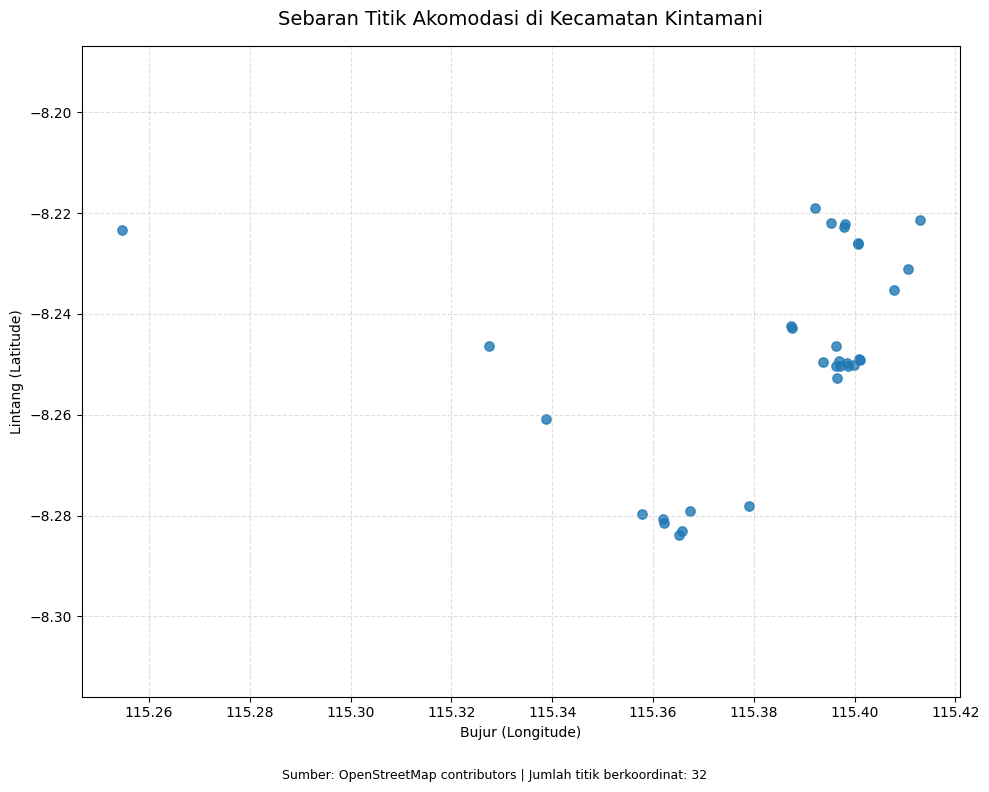

PNG berhasil dibuat: /content/drive/MyDrive/akomodasi_kintamani_2501010062/reports/peta_akomodasi_kintamani.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/akomodasi_kintamani_2501010062")
csv_path = PROJECT / "data/interim/akomodasi_kintamani.csv"
output = PROJECT / "reports/peta_akomodasi_kintamani.png"

df = pd.read_csv(csv_path)

df["lat"] = pd.to_numeric(df["lat"], errors="coerce")
df["lon"] = pd.to_numeric(df["lon"], errors="coerce")

peta_df = df.dropna(subset=["lat", "lon"]).copy()
peta_df = peta_df[
    peta_df["lat"].between(-90, 90) &
    peta_df["lon"].between(-180, 180)
]

if peta_df.empty:
    print("Tidak ada koordinat valid.")
else:
    fig, ax = plt.subplots(figsize=(10, 8))

    ax.scatter(
        peta_df["lon"],
        peta_df["lat"],
        s=45,
        alpha=0.8
    )

    ax.set_title(
        "Sebaran Titik Akomodasi di Kecamatan Kintamani",
        fontsize=14,
        pad=15
    )
    ax.set_xlabel("Bujur (Longitude)")
    ax.set_ylabel("Lintang (Latitude)")
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.set_aspect("equal", adjustable="datalim")

    fig.text(
        0.5, 0.02,
        f"Sumber: OpenStreetMap contributors | "
        f"Jumlah titik berkoordinat: {len(peta_df)}",
        ha="center",
        fontsize=9
    )

    plt.tight_layout(rect=[0, 0.05, 1, 1])
    plt.savefig(output, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    print("PNG berhasil dibuat:", output)

In [ ]:
!pip install pymupdf

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.0/69.0 MB 41.3 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 63.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [pymupdf]


In [ ]:

from pathlib import Path
from PIL import Image
import fitz  # PyMuPDF

PROJECT = Path(
    "/content/drive/MyDrive/akomodasi_kintamani_2501010062"
)

pdf_path = PROJECT / "reports/laporan_akuisisi_akomodasi.pdf"
png_path = PROJECT / "reports/peta_akomodasi_kintamani.png"
output_path = PROJECT / "reports/laporan_akuisisi_akomodasi_dengan_peta.pdf"

# Pastikan kedua file tersedia
if not pdf_path.exists():
    raise FileNotFoundError(
        f"PDF laporan belum ditemukan: {pdf_path}"
    )

if not png_path.exists():
    raise FileNotFoundError(
        f"PNG peta belum ditemukan: {png_path}. "
        "Buat gambar peta terlebih dahulu."
    )

# Buka laporan dan tambahkan satu halaman peta
doc = fitz.open(pdf_path)
page = doc.new_page(width=595.28, height=841.89)  # A4

page.insert_text(
    (50, 55),
    "Peta Sebaran Akomodasi di Kecamatan Kintamani",
    fontsize=16,
    fontname="helv"
)

page.insert_text(
    (50, 80),
    "Sumber data: OpenStreetMap contributors",
    fontsize=9,
    fontname="helv"
)

# Tempatkan gambar agar proporsinya tetap terjaga
img = Image.open(png_path)
img_width, img_height = img.size

area = fitz.Rect(40, 115, 555, 730)
scale = min(
    area.width / img_width,
    area.height / img_height
)

width = img_width * scale
height = img_height * scale

rect = fitz.Rect(
    (595.28 - width) / 2,
    115 + (615 - height) / 2,
    (595.28 + width) / 2,
    115 + (615 + height) / 2
)

page.insert_image(rect, filename=str(png_path))

page.insert_text(
    (50, 790),
    "Catatan: titik menggambarkan lokasi akomodasi yang tercatat "
    "dalam dataset OpenStreetMap hasil akuisisi.",
    fontsize=8,
    fontname="helv"
)

doc.save(output_path, garbage=4, deflate=True)
doc.close()

print("Berhasil! Laporan dengan halaman peta tersimpan di:")
print(output_path)



/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


Berhasil! Laporan dengan halaman peta tersimpan di:
/content/drive/MyDrive/akomodasi_kintamani_2501010062/reports/laporan_akuisisi_akomodasi_dengan_peta.pdf
